# E-Commerce Customer Segmentation & Sales Performance Analysis
**Author:** Aaditya Shukla – B.Tech 1st Year (CSE - AIML), ABES Engineering College  
**Tools:** Python, pandas, NumPy, matplotlib, seaborn  

### Project Objectives
1. Inspect and clean raw e-commerce transaction data (duplicates, text formatting, outliers, missing values).
2. Analyze overall sales performance, monthly revenue trends, and return/cancellation rates.
3. Evaluate category and regional revenue drivers along with discount impact.
4. Perform **RFM (Recency, Frequency, Monetary)** analysis to segment customers into actionable groups and propose retention strategies.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams['figure.dpi'] = 120

df_raw = pd.read_csv("../data/raw/ecommerce_sales_data.csv")
print("Raw Dataset Shape:", df_raw.shape)
print(df_raw.head())


Raw Dataset Shape: (371, 15)
   Order_ID  Order_Date Customer_ID   Age Gender Region        Category       Product_Name  Quantity  Unit_Price  Discount_Pct  Total_Sales Payment_Method Order_Status  Customer_Rating
0  ORD_5194  2026-08-27   CUST_1059  30.0   Male   West    Electronics   Bluetooth Speaker         1        1899           5.0      1804.05     Debit Card    Delivered              5.0
1  ORD_5034  2026-10-25   CUST_1011   NaN   Male  South     Electronics  Bluetooth Speaker         4        1899          10.0      6836.40     Debit Card     Returned              2.6
2  ORD_5016  2026-09-06   CUST_1006  18.0   Male  North         Fashion     Cotton T-Shirt         1         699           5.0       664.05     Debit Card    Delivered              2.8
3  ORD_5310  2026-09-25   CUST_1101  39.0   Male  South   Beauty & Care     Skincare Combo         1        1199           5.0      1139.05    Credit Card     Returned              2.0
4  ORD_5058  2026-10-19   CUST_1017  26.0   Ma

## 1. Data Inspection & Cleaning


In [2]:
print("Duplicate rows:", df_raw.duplicated().sum())
print("\nMissing values per column:\n", df_raw.isnull().sum()[df_raw.isnull().sum() > 0])
print("\nUnique Region values (raw):", df_raw['Region'].unique())
print("Unique Category values (raw):", df_raw['Category'].unique())


Duplicate rows: 6

Missing values per column:
Age                10
Discount_Pct        8
Payment_Method      5
Customer_Rating    14

Unique Region values (raw): ['West' 'South' 'North' 'East' 'north' ' west' 'South ' ' south' ' north'
 'SOUTH']
Unique Category values (raw): ['Electronics ' 'Electronics' 'Fashion' 'Beauty & Care' 'Home & Kitchen'
 'Books & Stationery' 'books & stationery' 'Beauty & Care '
 'Books & Stationery ' ' home & kitchen' 'beauty & care' 'Fashion '
 ' fashion' 'FASHION' 'BEAUTY & CARE']


In [3]:
df = df_raw.copy()
df = df.drop_duplicates().reset_index(drop=True)

df['Region'] = df['Region'].astype(str).str.strip().str.title()
df['Category'] = df['Category'].astype(str).str.strip().str.title()
df['Category'] = df['Category'].replace({
    'Home & Kitchen': 'Home & Kitchen',
    'Beauty & Care': 'Beauty & Care',
    'Books & Stationery': 'Books & Stationery'
})

df.loc[(df['Age'] < 15) | (df['Age'] > 100), 'Age'] = np.nan
df['Quantity'] = df['Quantity'].abs()
df.loc[(df['Discount_Pct'] < 0) | (df['Discount_Pct'] > 100), 'Discount_Pct'] = np.nan

df['Age'] = df['Age'].fillna(df['Age'].median()).astype(int)
df['Discount_Pct'] = df['Discount_Pct'].fillna(df['Discount_Pct'].median())
df['Payment_Method'] = df['Payment_Method'].fillna(df['Payment_Method'].mode()[0])
df['Customer_Rating'] = df.groupby('Order_Status')['Customer_Rating'].transform(
    lambda x: x.fillna(round(x.median(), 1))
)

df['Total_Sales'] = np.round(df['Unit_Price'] * df['Quantity'] * (1 - df['Discount_Pct'] / 100.0), 2)
df['Order_Date'] = pd.to_datetime(df['Order_Date'])
df['Order_Month'] = df['Order_Date'].dt.to_period('M').astype(str)

df.to_csv("../data/processed/ecommerce_sales_clean.csv", index=False)
print("Cleaned Dataset Shape:", df.shape)
print("Remaining Nulls:", df.isnull().sum().sum())


Cleaned Dataset Shape: (365, 16)
Remaining Nulls: 0


## 2. Overall Sales Performance & Monthly Trends


Total Orders: 365 | Delivered Orders: 249
Return/Cancellation Rate: 31.8%
Net Delivered Revenue: INR 788,884.35
Average Order Value (AOV): INR 3,168.21


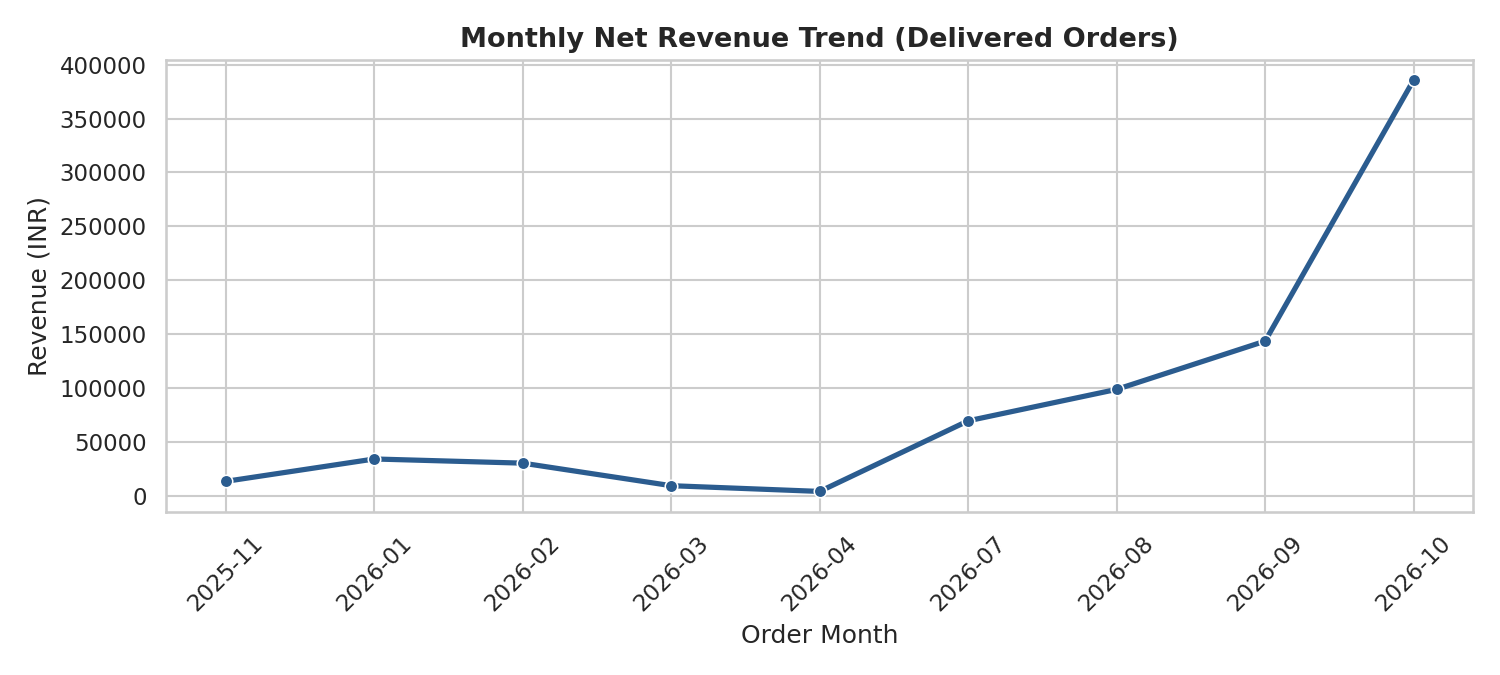

In [4]:
delivered_df = df[df['Order_Status'] == 'Delivered'].copy()

total_orders = len(df)
delivered_orders = len(delivered_df)
return_cancel_rate = ((total_orders - delivered_orders) / total_orders) * 100
net_revenue = delivered_df['Total_Sales'].sum()
aov = delivered_df['Total_Sales'].mean()

print(f"Total Orders: {total_orders} | Delivered Orders: {delivered_orders}")
print(f"Return/Cancellation Rate: {return_cancel_rate:.1f}%")
print(f"Net Delivered Revenue: INR {net_revenue:,.2f}")
print(f"Average Order Value (AOV): INR {aov:,.2f}")

monthly_sales = delivered_df.groupby('Order_Month')['Total_Sales'].sum().reset_index()
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.lineplot(data=monthly_sales, x='Order_Month', y='Total_Sales', marker='o', linewidth=2.5, color='#2b5c8f', ax=ax)
ax.set_title("Monthly Net Revenue Trend (Delivered Orders)", fontsize=13, fontweight='bold')
ax.set_xlabel("Order Month")
ax.set_ylabel("Revenue (INR)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../images/01_monthly_sales_performance.png", dpi=150)
plt.show()


## 3. Category & Regional Revenue Drivers


          Category  Total_Sales
       Electronics    256243.95
    Home & Kitchen    238809.50
           Fashion    186087.95
     Beauty & Care     69768.65
Books & Stationery     37974.30


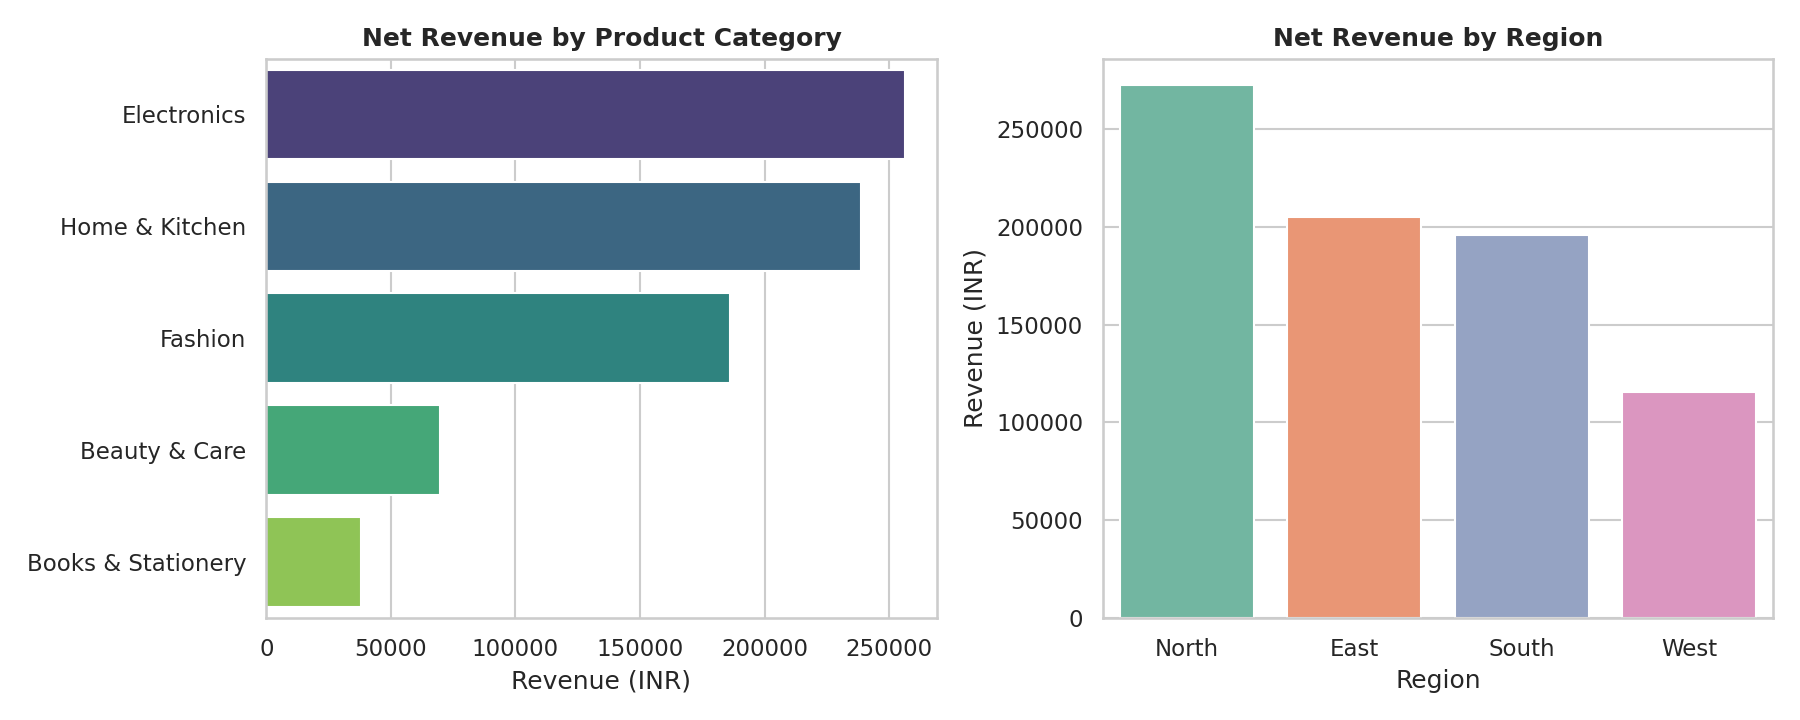

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
cat_rev = delivered_df.groupby('Category')['Total_Sales'].sum().sort_values(ascending=False).reset_index()
sns.barplot(data=cat_rev, x='Total_Sales', y='Category', palette='viridis', ax=axes[0])
axes[0].set_title("Net Revenue by Product Category", fontsize=12, fontweight='bold')

reg_rev = delivered_df.groupby('Region')['Total_Sales'].sum().sort_values(ascending=False).reset_index()
sns.barplot(data=reg_rev, x='Region', y='Total_Sales', palette='Set2', ax=axes[1])
axes[1].set_title("Net Revenue by Region", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig("../images/02_category_regional_performance.png", dpi=150)
plt.show()
print(cat_rev)


## 4. Customer Segmentation (RFM Analysis)


                 Customers  Avg_Recency_Days  Avg_Frequency  Avg_Spend_INR  Total_Segment_Revenue
Segment                                                                                          
Champions / VIP         31               8.6            4.9        19646.0               609025.6
Loyal Customers         56              28.0            2.9         7899.8               442386.7
At Risk                 20             251.4            1.8         5654.4               113088.2
New / Potential         13              19.7            1.0         2700.4                35105.8


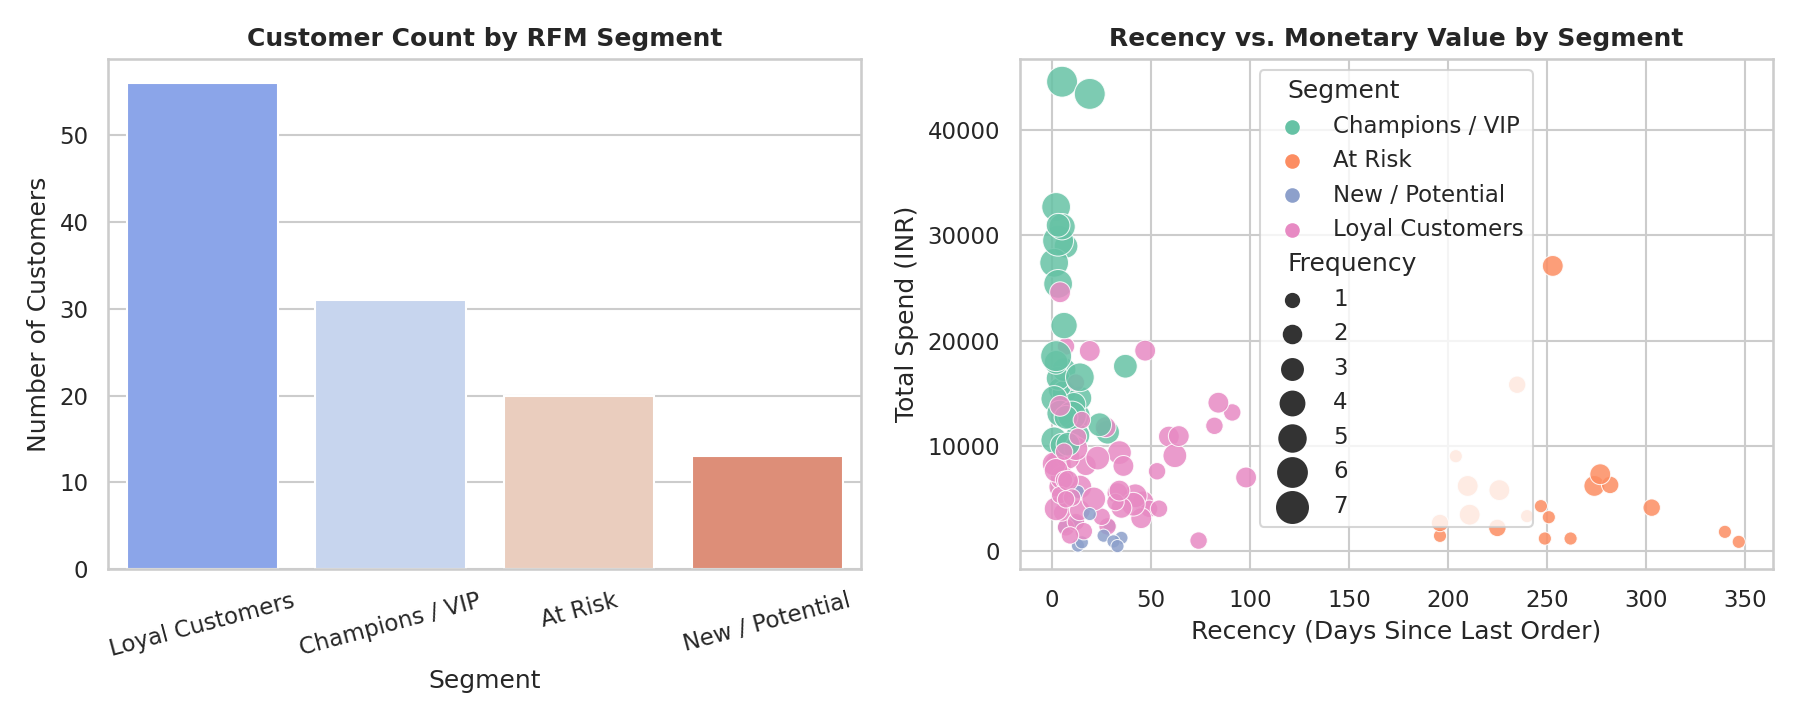

In [6]:
snapshot_date = df['Order_Date'].max() + pd.Timedelta(days=1)
rfm = df.groupby('Customer_ID').agg(
    Recency=('Order_Date', lambda x: (snapshot_date - x.max()).days),
    Frequency=('Order_ID', 'count'),
    Monetary=('Total_Sales', 'sum')
).reset_index()

def assign_segment(row):
    if row['Recency'] > 150:
        return 'At Risk'
    elif row['Frequency'] >= 4 and row['Monetary'] >= 10000:
        return 'Champions / VIP'
    elif row['Frequency'] >= 2:
        return 'Loyal Customers'
    else:
        return 'New / Potential'

rfm['Segment'] = rfm.apply(assign_segment, axis=1)
seg_summary = rfm.groupby('Segment').agg(
    Customers=('Customer_ID', 'count'),
    Avg_Recency_Days=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Spend_INR=('Monetary', 'mean'),
    Total_Segment_Revenue=('Monetary', 'sum')
).round(1).sort_values(by='Total_Segment_Revenue', ascending=False)
print(seg_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
seg_counts = rfm['Segment'].value_counts().reset_index()
seg_counts.columns = ['Segment', 'Count']
sns.barplot(data=seg_counts, x='Segment', y='Count', palette='coolwarm', ax=axes[0])
axes[0].set_title("Customer Count by RFM Segment", fontsize=12, fontweight='bold')

sns.scatterplot(data=rfm, x='Recency', y='Monetary', hue='Segment', size='Frequency', sizes=(40, 220), alpha=0.85, ax=axes[1])
axes[1].set_title("Recency vs. Monetary Value by Segment", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig("../images/03_rfm_customer_segmentation.png", dpi=150)
plt.show()


## 5. Discount Impact & Customer Satisfaction


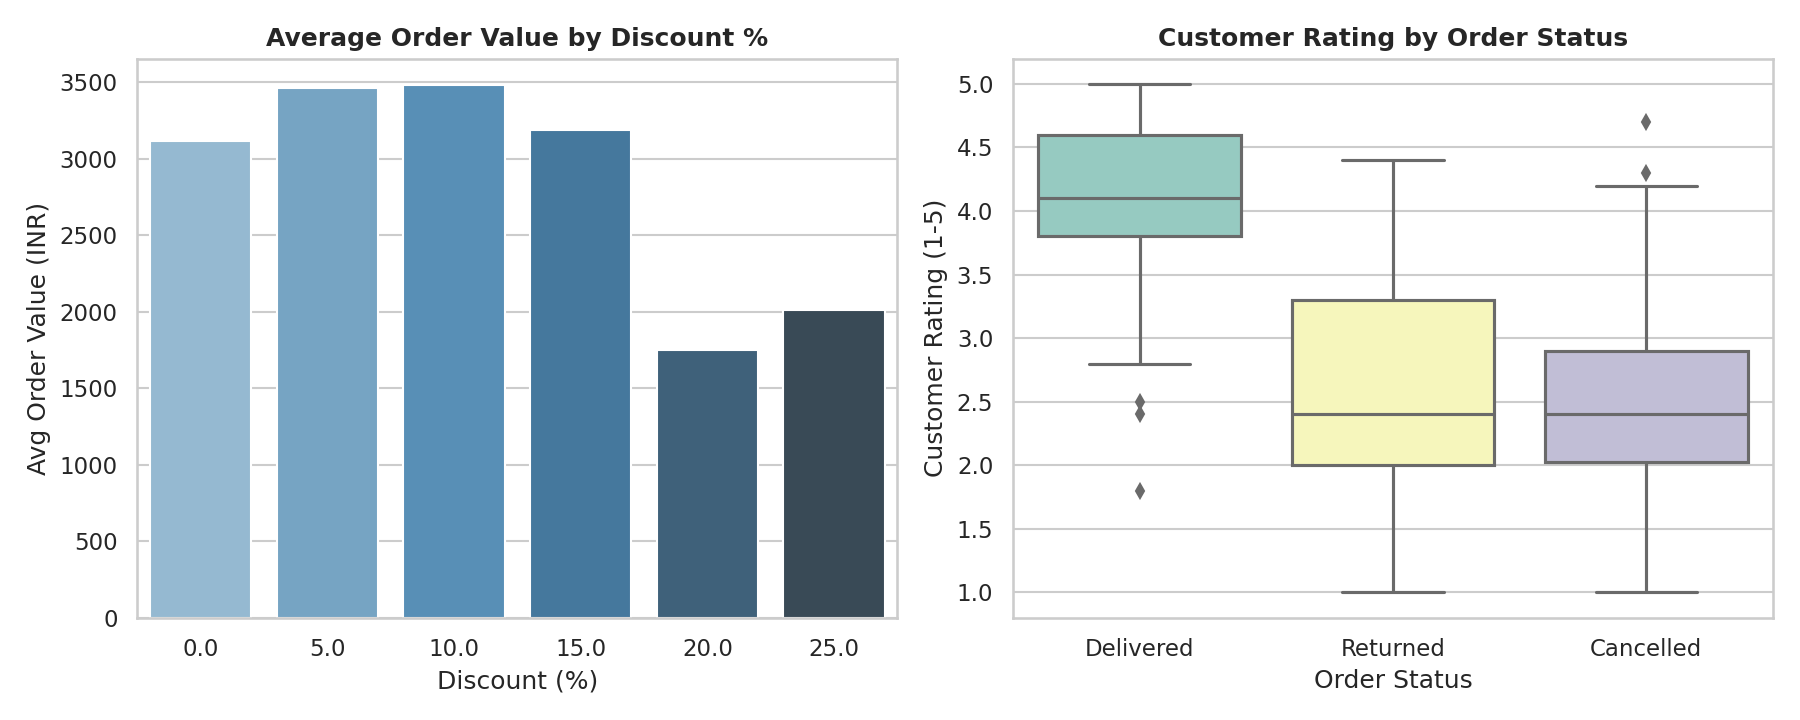

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
disc_sales = delivered_df.groupby('Discount_Pct')['Total_Sales'].mean().reset_index()
sns.barplot(data=disc_sales, x='Discount_Pct', y='Total_Sales', palette='Blues_d', ax=axes[0])
axes[0].set_title("Average Order Value by Discount %", fontsize=12, fontweight='bold')

sns.boxplot(data=df, x='Order_Status', y='Customer_Rating', palette='Set3', ax=axes[1])
axes[1].set_title("Customer Rating by Order Status", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig("../images/04_discount_rating_behavior.png", dpi=150)
plt.show()
